# Mission 1: Wine Type Classification
## 1. The Idea
This model predicts which of 3 grape cultivars (class 0, 1 or 2) a wine comes from, using 13 chemical measurements (alcohol, flavanoids, color intensity, etc.).

**Why it is useful:** wine makers and quality labs can verify a wine's origin and detect mislabelled or adulterated bottles from a quick lab test, without needing a human expert taster.

## 2. Data Preparation

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

data = load_wine(as_frame=True)
df = data.frame
print(df.shape)
df.head()

(178, 14)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [12]:
# Check for missing values
print(df.isnull().sum().sum(), "missing values")
df['target'].value_counts()

0 missing values


,count
target,
1,71
0,59
2,48


In [13]:
# Features and target
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# KNN is distance-based, so scale the features
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## 3. Model Building

In [14]:
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)
knn_pred = knn.predict(X_test_s)

## 4. Evaluation

Decision Tree accuracy: 0.944
KNN accuracy:           0.972


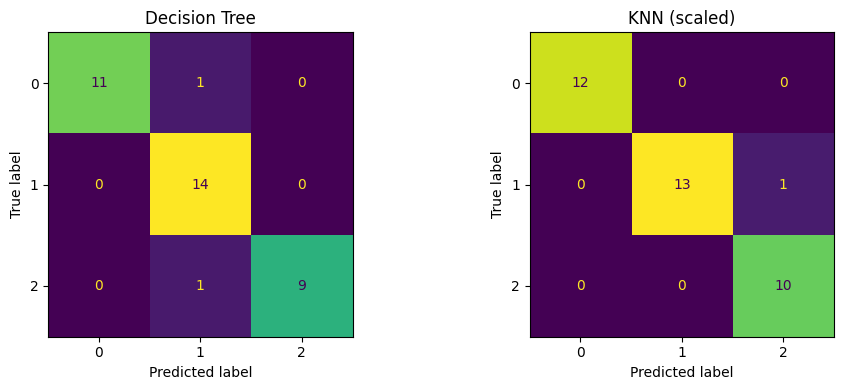

In [15]:
dt_acc = accuracy_score(y_test, dt_pred)
knn_acc = accuracy_score(y_test, knn_pred)
print(f"Decision Tree accuracy: {dt_acc:.3f}")
print(f"KNN accuracy:           {knn_acc:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, dt_pred, ax=ax[0], colorbar=False)
ax[0].set_title("Decision Tree")
ConfusionMatrixDisplay.from_predictions(y_test, knn_pred, ax=ax[1], colorbar=False)
ax[1].set_title("KNN (scaled)")
plt.tight_layout()
plt.show()

## 5. Conclusion
 *KNN scored higher with an accuracy of 0.972 against 0.944 for the decision tree. On the 36 test samples, KNN made only 1 mistake(class 1 wine predicted as class 2), while Decision Tree made 2(one class 0 as class 1 and one class 2 as class 1). Gap is small as its only one model so both classify cultivars very well from chemical measurements. KNN likely did better because the features were scaled, so large value features like proline didn't dominate distance calculations. Decision Tree is easier to explain but it can overfit. What we can learn: feature scaling matters for distance based models like KNN, a confusion matrix shows which classes get mixed up, which accuracy alone does not.*